# Preentrega 14: Análisis visual de distribuciones categóricas y outliers

**Objetivo:** caracterizar las variables de un dataset de propinas de restaurante: ver la forma de las distribuciones, medir asimetría y curtosis y detectar valores atípicos (outliers) con el método del rango intercuartílico (IQR).

**Origen de los datos:** `data/propinas.csv`, dataset **simulado** con la misma estructura que el dataset `tips` de Seaborn (generado con `generar_dataset.py`).

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis

sns.set_theme(style="whitegrid")

## 1. Carga y limpieza

In [2]:
df = pd.read_csv("data/propinas.csv")
print("Dimensiones:", df.shape)
print("\nNulos por columna:\n", df.isna().sum())
print("\nDuplicados:", df.duplicated().sum())
df.describe().round(2)

Dimensiones: (400, 7)

Nulos por columna:
 cuenta_total    0
propina         0
sexo            0
fumador         0
dia             0
momento         0
personas        0
dtype: int64

Duplicados: 2


,cuenta_total,propina,personas
count,400.00,400.00,400.00
mean,20.78,3.24,2.72
std,13.26,2.26,1.09
min,4.00,0.50,1.00
25%,10.40,1.47,2.00
50%,18.36,2.84,2.00
75%,28.54,4.24,3.00
max,74.73,12.34,6.00


## 2. Variables categóricas: gráficos de barras

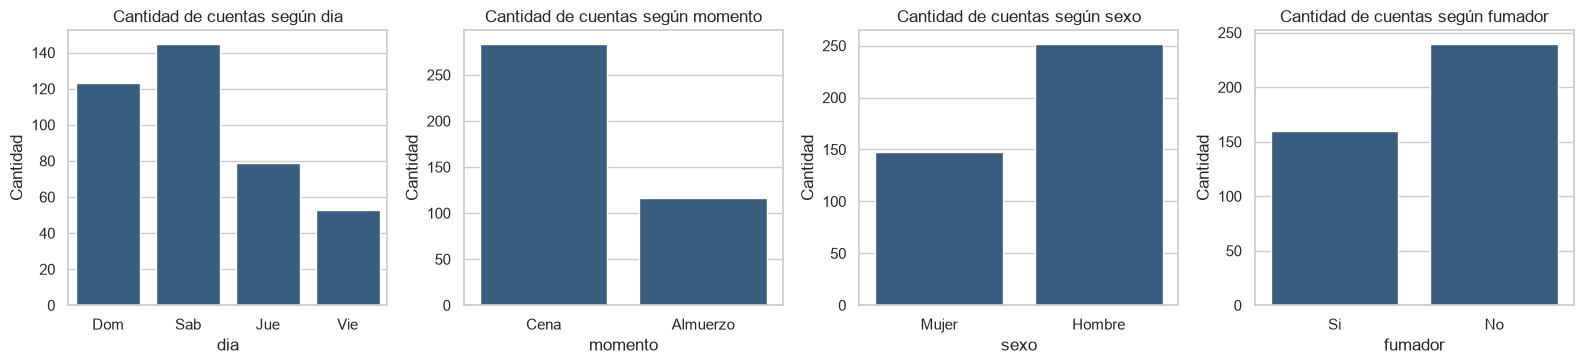

In [3]:
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.8))
for eje, col in zip(ejes, ["dia", "momento", "sexo", "fumador"]):
    sns.countplot(data=df, x=col, ax=eje, color="#2E5C8A")
    eje.set_title(f"Cantidad de cuentas según {col}")
    eje.set_ylabel("Cantidad")
plt.tight_layout()
plt.show()

## 3. Forma de las distribuciones numéricas: asimetría (skewness) y curtosis
- **Asimetría > 0:** cola larga hacia la **derecha** (muchos valores bajos y pocos muy altos).
- **Asimetría < 0:** cola larga hacia la **izquierda**.
- **Curtosis (exceso) > 0:** colas más pesadas que la normal, con más valores extremos.

In [4]:
columnas_num = ["cuenta_total", "propina", "personas"]
resumen = pd.DataFrame({
    "media": df[columnas_num].mean(),
    "mediana": df[columnas_num].median(),
    "desvio": df[columnas_num].std(),
    "asimetria": [skew(df[c]) for c in columnas_num],
    "curtosis": [kurtosis(df[c]) for c in columnas_num],   # curtosis en exceso (normal = 0)
}).round(3)
resumen

,media,mediana,desvio,asimetria,curtosis
cuenta_total,20.782,18.355,13.260,1.065,1.073
propina,3.239,2.840,2.257,1.349,2.131
personas,2.720,2.000,1.088,1.121,0.739


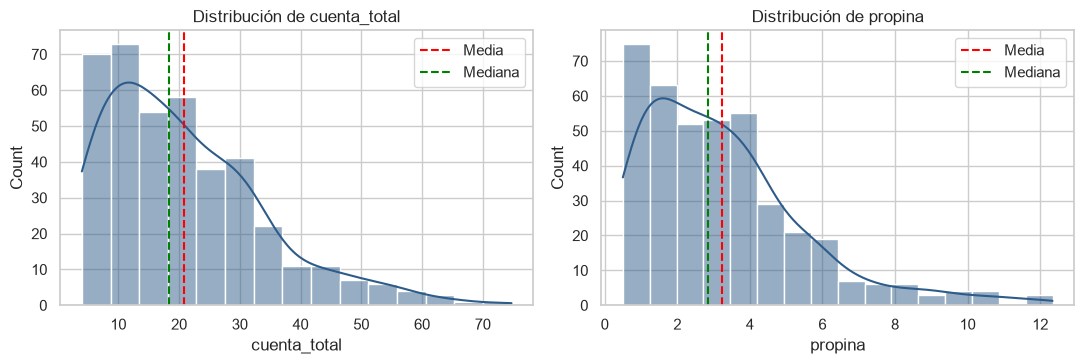

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for eje, col in zip(ejes, ["cuenta_total", "propina"]):
    sns.histplot(df[col], kde=True, ax=eje, color="#2E5C8A")
    eje.axvline(df[col].mean(), color="red", ls="--", label="Media")
    eje.axvline(df[col].median(), color="green", ls="--", label="Mediana")
    eje.set_title(f"Distribución de {col}")
    eje.legend()
plt.tight_layout()
plt.show()

**Lectura:** `cuenta_total` tiene asimetría **1.06** (positiva, cola a la derecha) y curtosis **1.07**: la media (20.8) queda por encima de la mediana (18.4) porque unas pocas cuentas muy altas la empujan hacia arriba.

## 4. Outliers: boxplots y violin plots

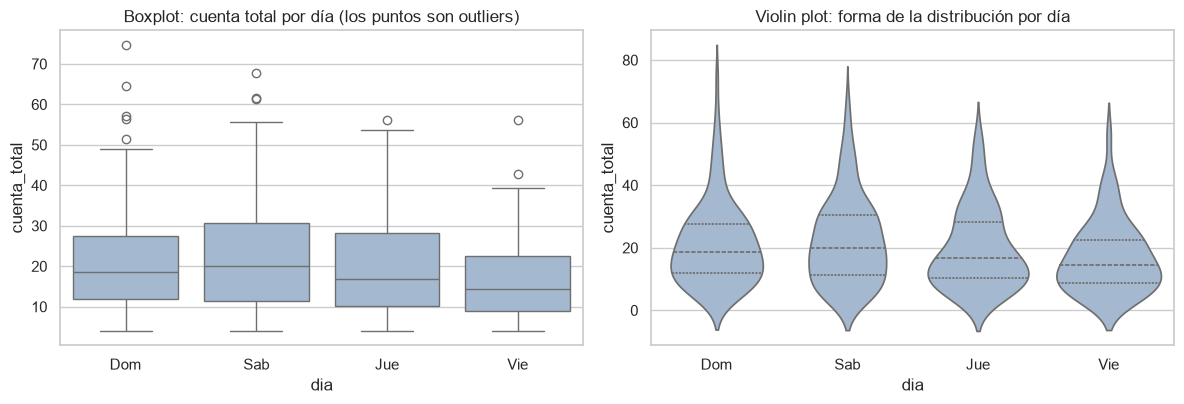

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=df, x="dia", y="cuenta_total", color="#9DB8D6", ax=ejes[0])
ejes[0].set_title("Boxplot: cuenta total por día (los puntos son outliers)")
sns.violinplot(data=df, x="dia", y="cuenta_total", color="#9DB8D6", inner="quartile", ax=ejes[1])
ejes[1].set_title("Violin plot: forma de la distribución por día")
plt.tight_layout()
plt.show()

## 5. Detección de outliers con el método IQR
Un valor es atípico si está **por debajo de Q1 − 1.5·IQR** o **por encima de Q3 + 1.5·IQR**, donde IQR = Q3 − Q1.

In [7]:
def detectar_outliers_iqr(serie):
    """Devuelve los límites inferior y superior según la regla del IQR."""
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    return limite_inf, limite_sup

lim_inf, lim_sup = detectar_outliers_iqr(df["cuenta_total"])
print(f"Límites IQR para cuenta_total: [{lim_inf:.2f} , {lim_sup:.2f}]")

# Segmentación: marcamos cada fila como outlier o no
df["es_outlier"] = (df["cuenta_total"] < lim_inf) | (df["cuenta_total"] > lim_sup)
print("Cantidad de outliers:", df["es_outlier"].sum(), "de", len(df), f"({df['es_outlier'].mean():.1%})")
df[df["es_outlier"]].sort_values("cuenta_total", ascending=False)

Límites IQR para cuenta_total: [-16.82 , 55.75]
Cantidad de outliers: 9 de 400 (2.2%)


,cuenta_total,propina,sexo,fumador,dia,momento,personas,es_outlier
151,74.73,12.34,Mujer,No,Dom,Almuerzo,6,True
288,67.68,12.03,Hombre,No,Sab,Cena,4,True
397,64.45,10.77,Hombre,Si,Dom,Cena,6,True
209,61.63,11.82,Hombre,No,Sab,Almuerzo,4,True
48,61.32,10.82,Hombre,No,Sab,Cena,5,True
389,57.17,9.67,Hombre,No,Dom,Cena,4,True
2,56.44,6.97,Hombre,Si,Dom,Almuerzo,3,True
330,56.05,10.75,Mujer,No,Vie,Cena,2,True
11,56.02,9.38,Hombre,Si,Jue,Almuerzo,6,True


In [8]:
# Comparación con y sin outliers
sin_out = df[~df["es_outlier"]]
comparacion = pd.DataFrame({
    "Con outliers": [df["cuenta_total"].mean(), df["cuenta_total"].std(), skew(df["cuenta_total"])],
    "Sin outliers": [sin_out["cuenta_total"].mean(), sin_out["cuenta_total"].std(), skew(sin_out["cuenta_total"])],
}, index=["Media", "Desvío", "Asimetría"]).round(3)
comparacion

,Con outliers,Sin outliers
Media,20.782,19.840
Desvío,13.260,11.811
Asimetría,1.065,0.755


## 6. Conclusiones
- Hay **9 cuentas atípicas** (2.2%). Al quitarlas, la asimetría baja de 1.06 a 0.76 y la media de 20.78 a 19.84.
- 7 de los 9 outliers ocurren en fin de semana, y las mesas atípicas tienen en promedio 4.4 personas frente a 2.7 en general: son grupos grandes, no errores.
- **Decisión sugerida:** no eliminarlos automáticamente. Son cuentas reales de grupos grandes, no errores de carga. Para modelar conviene **transformarlos** (por ejemplo, logaritmo) o usar medidas robustas como la mediana.